# 6BUIS017W CWK1 - Task 2: Stock segmentation and sensitivity analysis
Needs `data/features_task1.csv` from the Task 1 notebook (same repo folder). Run top to bottom.
Figures go to `figures/`, tables and cluster assignments to `data/`.

| Section | Brief item |
|---|---|
| 1 | 2.1 feature matrices, skew/outliers, log1p(M), standardisation |
| 2 | 2.2 Ward agglomerative, dendrograms, k = 2-8 |
| 3 | 2.3 K-means, k = 2-8, multiple initialisations |
| 4 | 2.4 profiles (original units), 2D visuals, algorithm comparison |
| 5 | 2.5 correlations and removal of Monetary |

In [ ]:
# STEP 0 - bring in the Task 1 output (this notebook runs in its own Colab runtime).
# When prompted, choose features_task1.csv (downloaded by the Task 1 notebook).
from pathlib import Path
Path("data").mkdir(exist_ok=True)
if not Path("data/features_task1.csv").exists():
    from google.colab import files
    for name, content in files.upload().items():
        if name.startswith("features_task1"):               # tolerates browser renames like 'features_task1 (1).csv'
            Path("data/features_task1.csv").write_bytes(content)
print("features_task1.csv present:", Path("data/features_task1.csv").exists())
assert Path("data/features_task1.csv").exists(), "Upload features_task1.csv from Task 1 first"


features_task1.csv present: True


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from importlib.metadata import version
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

for p in ["pandas", "numpy", "scikit-learn", "scipy", "matplotlib"]: print(f"{p:14s}{version(p)}")
DATA, FIG = Path("data"), Path("figures"); FIG.mkdir(exist_ok=True)
SEED, N_INIT, KS = 42, 50, range(2, 9)          # fixed seed, 50 K-means initialisations, k = 2..8
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

pandas        2.2.3
numpy         2.4.6
scikit-learn  1.6.1
scipy         1.16.3
matplotlib    3.10.0


## 1. Feature preparation (2.1)
Two **separate** matrices on the **same shares**:
- risk/return: mean weekly return, weekly beta
- trading activity: R, F, log1p(M)

`log1p` is applied to M only (as required); each matrix is then standardised on its own (z-scores). R, F, return and beta are left in their raw units - see the skew table for why.

In [ ]:
feat = pd.read_csv(DATA / "features_task1.csv", index_col="Ticker", parse_dates=["Last_Event_Date"])
need = ["Mean_Weekly_Return", "Weekly_Beta", "R", "F", "M"]
feat = feat.dropna(subset=need)                              # common share set for ALL solutions
print("Shares in the common set:", len(feat))

X_rr_raw  = feat[["Mean_Weekly_Return", "Weekly_Beta"]]
X_rfm_raw = pd.DataFrame({"R": feat["R"], "F": feat["F"], "log1p_M": np.log1p(feat["M"])})
assert X_rr_raw.index.equals(X_rfm_raw.index)

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

diag = pd.DataFrame({
    "skew": pd.concat([X_rr_raw, X_rfm_raw], axis=1).skew(),
    "IQR_outliers": pd.concat([X_rr_raw, X_rfm_raw], axis=1).apply(iqr_outliers),
    "max_abs_z": pd.concat([X_rr_raw, X_rfm_raw], axis=1).apply(lambda s: ((s - s.mean()) / s.std()).abs().max())}).round(2)
diag.loc["M (raw, before log1p)"] = [round(feat["M"].skew(), 2), iqr_outliers(feat["M"]), round(((feat["M"]-feat["M"].mean())/feat["M"].std()).abs().max(), 2)]
print(diag.to_string())

Shares in the common set: 485
                        skew  IQR_outliers  max_abs_z
Mean_Weekly_Return      0.88          15.0       5.64
Weekly_Beta             1.11          10.0       6.91
R                       3.64         118.0       9.44
F                       0.43           2.0       3.77
log1p_M                 1.08          13.0       4.84
M (raw, before log1p)  11.67          45.0      13.99


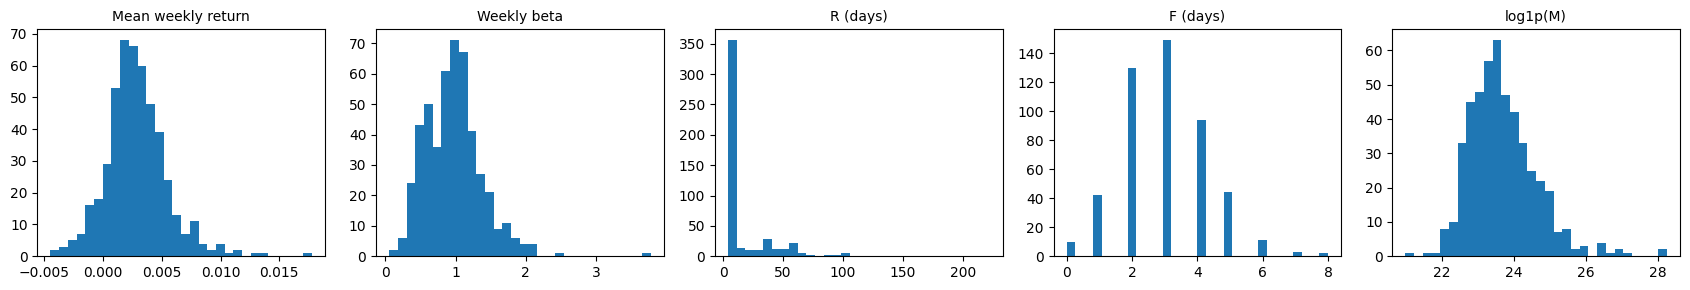

RR  means/stds : [-0. -0.] [1. 1.]
RFM means/stds : [ 0. -0. -0.] [1. 1. 1.]


In [ ]:
fig, ax = plt.subplots(1, 5, figsize=(17, 3))
for a, (name, s) in zip(ax, [("Mean weekly return", feat["Mean_Weekly_Return"]), ("Weekly beta", feat["Weekly_Beta"]),
                             ("R (days)", feat["R"]), ("F (days)", feat["F"]), ("log1p(M)", np.log1p(feat["M"]))]):
    a.hist(s, bins=30); a.set_title(name, fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "feature_distributions.png", dpi=150); plt.show()

sc_rr, sc_rfm = StandardScaler(), StandardScaler()
X_rr  = sc_rr.fit_transform(X_rr_raw)          # separate scaler per matrix
X_rfm = sc_rfm.fit_transform(X_rfm_raw)
print("RR  means/stds :", X_rr.mean(0).round(3), X_rr.std(0).round(3))
print("RFM means/stds :", X_rfm.mean(0).round(3), X_rfm.std(0).round(3))

## 2. Agglomerative clustering - Ward linkage, Euclidean distance (2.2)
**Suitability:** produces a nested hierarchy and needs no seed; Ward merges the pair of clusters that least increases within-cluster variance, so it favours compact, similar-sized groups. **Limitations:** greedy (merges are never undone), sensitive to outliers, O(n^2) memory, and the dendrogram does not choose k for you.

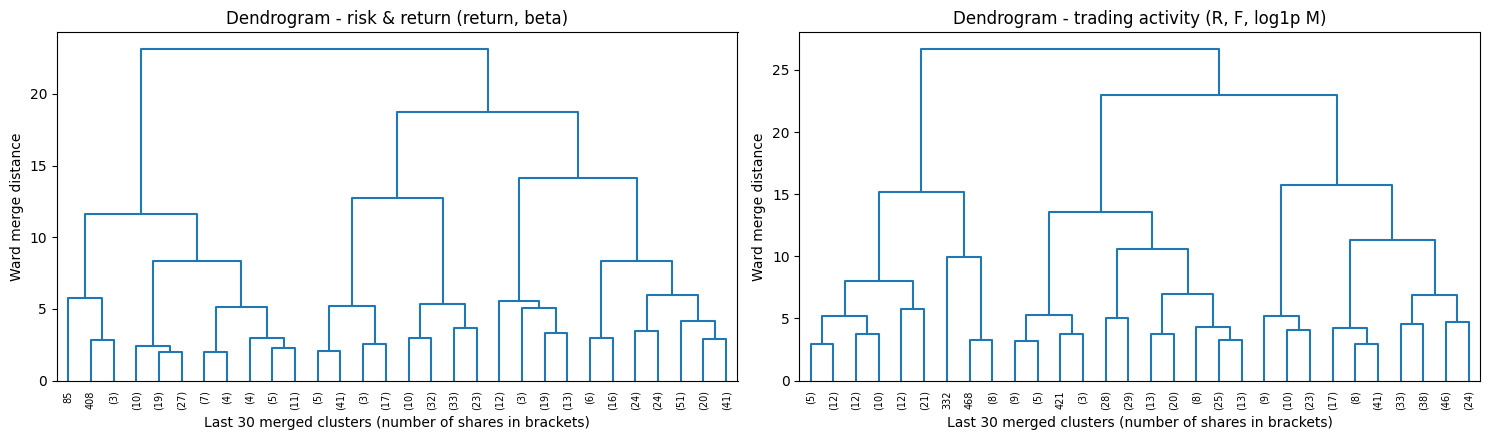

In [ ]:
Z_rr, Z_rfm = linkage(X_rr, method="ward"), linkage(X_rfm, method="ward")   # Ward uses Euclidean distance
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, Z, t in [(ax[0], Z_rr, "Dendrogram - risk & return (return, beta)"), (ax[1], Z_rfm, "Dendrogram - trading activity (R, F, log1p M)")]:
    dendrogram(Z, truncate_mode="lastp", p=30, no_labels=False, show_leaf_counts=True,
               leaf_rotation=90, leaf_font_size=7, ax=a, color_threshold=0)
    a.set_title(t); a.set_ylabel("Ward merge distance"); a.set_xlabel("Last 30 merged clusters (number of shares in brackets)")
plt.tight_layout(); plt.savefig(FIG / "dendrograms.png", dpi=150); plt.show()

In [ ]:
def sizes(lbl): return "/".join(str(n) for n in sorted(np.bincount(lbl), reverse=True))

def ward_table(X):
    rows = []
    for k in KS:
        lbl = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        rows.append(dict(k=k, silhouette=round(silhouette_score(X, lbl), 3), smallest=int(np.bincount(lbl).min()), sizes=sizes(lbl)))
    return pd.DataFrame(rows).set_index("k")

ward_rr, ward_rfm = ward_table(X_rr), ward_table(X_rfm)
print("WARD - risk & return\n", ward_rr.to_string(), "\n\nWARD - trading activity (RFM)\n", ward_rfm.to_string())

WARD - risk & return
    silhouette  smallest                    sizes
k                                               
2       0.341        92                   393/92
3       0.274        92               229/164/92
4       0.282        47            182/164/92/47
5       0.304        47          182/98/92/66/47
6       0.321         5        182/98/87/66/47/5
7       0.325         5     160/98/87/66/47/22/5
8       0.323         5  160/98/66/56/47/31/22/5 

WARD - trading activity (RFM)
    silhouette  smallest                     sizes
k                                                
2       0.368        82                    403/82
3       0.304        82                249/154/82
4       0.289        42             207/154/82/42
5       0.305        10          207/154/72/42/10
6       0.314        10       207/136/72/42/18/10
7       0.292        10    141/136/72/66/42/18/10
8       0.302        10  141/79/72/66/57/42/18/10


### Choosing k for Ward
k is chosen from silhouette scores, cluster sizes and interpretable profiles (section 4); the dendrogram colour threshold is not used to set k.

In [ ]:
# Chosen cluster counts (k = 3 for every solution; see report section 2.2)
K_WARD = {"rr": 3, "rfm": 3}     
K_KM   = {"rr": 3, "rfm": 3}
print("Selected k:", K_WARD, K_KM)

Selected k: {'rr': 3, 'rfm': 3} {'rr': 3, 'rfm': 3}


## 3. K-means (2.3)
**Suitability:** fast, simple, centroids are easy to read. **Limitations:** needs k in advance, assumes compact, roughly spherical, similar-sized clusters, sensitive to outliers and to scaling, and the result depends on initialisation - so we fix `random_state=42`, use `n_init=50` initialisations (best of 50 by inertia) and check repeatability across seeds.

K-MEANS - risk & return
    inertia  silhouette  smallest                    sizes  seed_stability_ARI
k                                                                            
2    617.0       0.389       143                  342/143               1.000
3    459.8       0.328       120              202/163/120               0.999
4    370.2       0.327        40           160/154/131/40               0.984
5    308.2       0.340        27        166/131/111/50/27               0.973
6    263.4       0.336         5      155/127/106/51/41/5               0.993
7    225.3       0.330         5    128/103/84/77/47/41/5               0.843
8    192.7       0.361         5  139/76/75/74/47/40/29/5               0.983 

K-MEANS - trading activity (RFM)
    inertia  silhouette  smallest                     sizes  seed_stability_ARI
k                                                                             
2   1064.4       0.423        68                    417/68               1.000


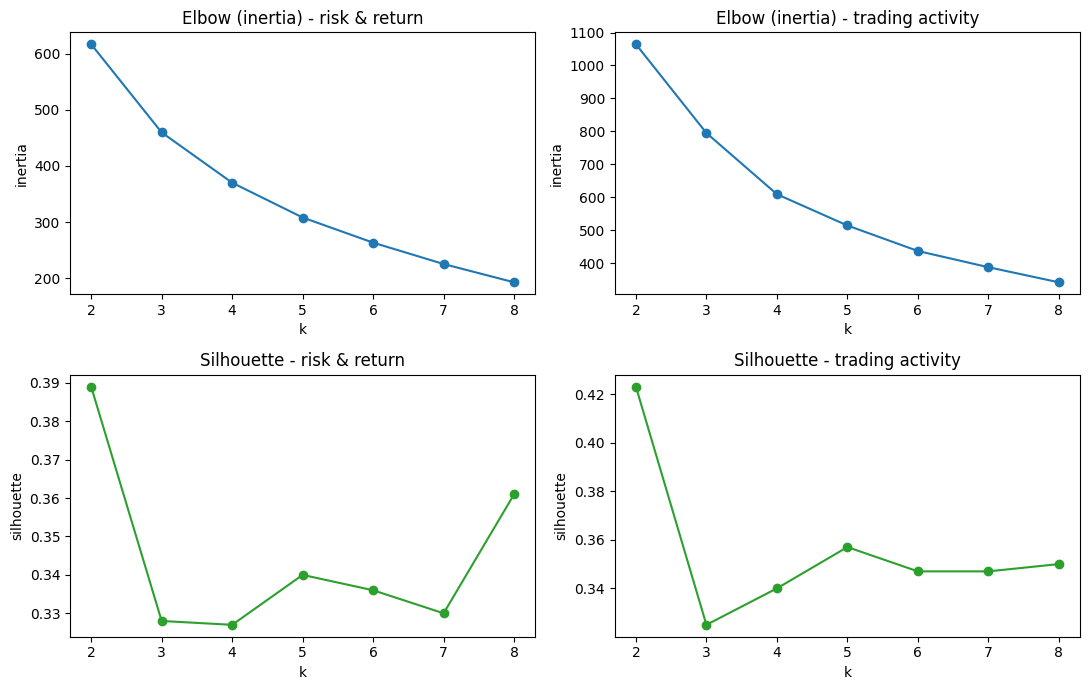

In [ ]:
def km_table(X):
    rows = []
    for k in KS:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)
        # repeatability: re-fit with 5 other seeds, mean ARI against the main solution
        aris = [adjusted_rand_score(km.labels_, KMeans(n_clusters=k, n_init=N_INIT, random_state=s).fit(X).labels_) for s in range(1, 6)]
        rows.append(dict(k=k, inertia=round(km.inertia_, 1), silhouette=round(silhouette_score(X, km.labels_), 3),
                         smallest=int(np.bincount(km.labels_).min()), sizes=sizes(km.labels_), seed_stability_ARI=round(float(np.mean(aris)), 3)))
    return pd.DataFrame(rows).set_index("k")

km_rr, km_rfm = km_table(X_rr), km_table(X_rfm)
print("K-MEANS - risk & return\n", km_rr.to_string(), "\n\nK-MEANS - trading activity (RFM)\n", km_rfm.to_string())

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for j, (tbl, name) in enumerate([(km_rr, "risk & return"), (km_rfm, "trading activity")]):
    ax[0, j].plot(tbl.index, tbl["inertia"], "o-"); ax[0, j].set_title(f"Elbow (inertia) - {name}"); ax[0, j].set_xlabel("k"); ax[0, j].set_ylabel("inertia")
    ax[1, j].plot(tbl.index, tbl["silhouette"], "o-", color="tab:green"); ax[1, j].set_title(f"Silhouette - {name}"); ax[1, j].set_xlabel("k"); ax[1, j].set_ylabel("silhouette")
plt.tight_layout(); plt.savefig(FIG / "kmeans_diagnostics.png", dpi=150); plt.show()

In [ ]:
# Side-by-side k diagnostics for k = 2 to 8
cmp = pd.concat({"Ward RR": ward_rr, "KM RR": km_rr, "Ward RFM": ward_rfm, "KM RFM": km_rfm}, axis=1)
print(cmp.loc[:, [c for c in cmp.columns if c[1] in ("silhouette", "smallest")]].to_string())


     Ward RR               KM RR            Ward RFM              KM RFM         
  silhouette smallest silhouette smallest silhouette smallest silhouette smallest
k                                                                                
2      0.341       92      0.389      143      0.368       82      0.423       68
3      0.274       92      0.328      120      0.304       82      0.325       64
4      0.282       47      0.327       40      0.289       42      0.340       61
5      0.304       47      0.340       27      0.305       10      0.357       11
6      0.321        5      0.336        5      0.314       10      0.347       11
7      0.325        5      0.330        5      0.292       10      0.347        1
8      0.323        5      0.361        5      0.302       10      0.350        1


## 4. Cluster profiles and algorithm comparison (2.4)
Cluster numbers are arbitrary labels; for readability they are re-ordered (risk & return: by mean beta, low to high; activity: by median traded value, low to high). Profiles are in **original units**. Mean M is dominated by a few mega-caps, so medians are shown as well.

In [ ]:
def relabel(lbl, key):
    order = pd.Series(key.values).groupby(lbl).median().sort_values().index
    m = {old: new for new, old in enumerate(order, start=1)}
    return np.array([m[x] for x in lbl])

sol = pd.DataFrame(index=feat.index)
sol["Ward_RR"]     = relabel(AgglomerativeClustering(n_clusters=K_WARD["rr"],  linkage="ward").fit_predict(X_rr),  feat["Weekly_Beta"])
sol["KMeans_RR"]   = relabel(KMeans(n_clusters=K_KM["rr"],  n_init=N_INIT, random_state=SEED).fit_predict(X_rr),  feat["Weekly_Beta"])
sol["Ward_RFM"]    = relabel(AgglomerativeClustering(n_clusters=K_WARD["rfm"], linkage="ward").fit_predict(X_rfm), feat["M"])
sol["KMeans_RFM"]  = relabel(KMeans(n_clusters=K_KM["rfm"], n_init=N_INIT, random_state=SEED).fit_predict(X_rfm), feat["M"])

def profile(col, kind):
    g = feat.groupby(sol[col])
    if kind == "rr":
        p = g.agg(n=("Weekly_Beta", "size"), mean_weekly_return_pct=("Mean_Weekly_Return", lambda s: 100*s.mean()), mean_beta=("Weekly_Beta", "mean"))
        p["beta_min"], p["beta_max"] = g["Weekly_Beta"].min(), g["Weekly_Beta"].max()
    else:
        p = g.agg(n=("R", "size"), R_median=("R", "median"), F_mean=("F", "mean"), M_median_usd_bn=("M", lambda s: s.median()/1e9), M_mean_usd_bn=("M", lambda s: s.mean()/1e9))
    return p.round(3)

profiles = {c: profile(c, "rr" if c.endswith("RR") else "rfm") for c in sol.columns}
for c, p in profiles.items(): print(f"\n{c}\n{p.to_string()}")


Ward_RR
           n  mean_weekly_return_pct  mean_beta  beta_min  beta_max
Ward_RR                                                            
1        164                   0.287      0.601     0.055     1.042
2        229                   0.148      1.106     0.579     2.505
3         92                   0.632      1.298     0.594     3.779

KMeans_RR
             n  mean_weekly_return_pct  mean_beta  beta_min  beta_max
KMeans_RR                                                            
1          202                   0.259      0.631     0.055     0.987
2          163                   0.095      1.133     0.555     2.505
3          120                   0.593      1.328     0.594     3.779

Ward_RFM
            n  R_median  F_mean  M_median_usd_bn  M_mean_usd_bn
Ward_RFM                                                       
1         249      11.0   3.353           11.154         11.753
2          82      54.5   2.098           17.849         47.159
3         154      11.0 

PCA explained variance: [0.458 0.337] | total: 0.795
PCA loadings (rows = PCs):
         R     F  log1p_M
PC1  0.71 -0.65     0.27
PC2  0.02  0.40     0.92


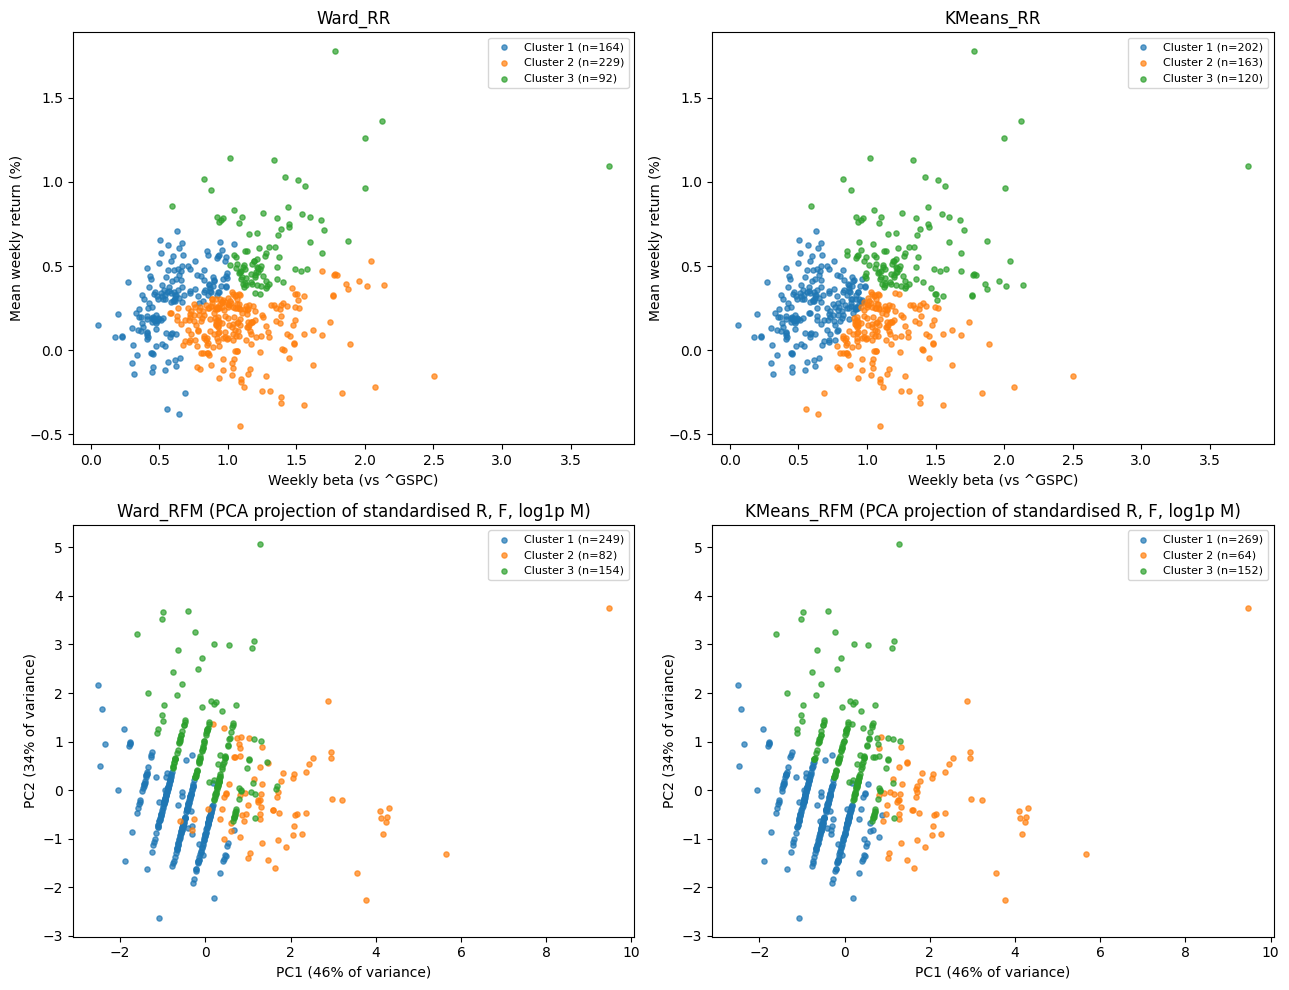

In [ ]:
# 2D visuals. Risk & return already has two features -> plot in original units.
# RFM has three features -> PCA (2 components of the standardised matrix) to project to 2D. Axes show how much variance each PC keeps.
pca = PCA(n_components=2, random_state=SEED).fit(X_rfm)
P = pca.transform(X_rfm)
print("PCA explained variance:", pca.explained_variance_ratio_.round(3), "| total:", pca.explained_variance_ratio_.sum().round(3))
print("PCA loadings (rows = PCs):\n", pd.DataFrame(pca.components_, columns=X_rfm_raw.columns, index=["PC1", "PC2"]).round(2).to_string())

fig, ax = plt.subplots(2, 2, figsize=(13, 10))
for a, col in zip(ax[0], ["Ward_RR", "KMeans_RR"]):
    for c in sorted(sol[col].unique()):
        m = sol[col] == c
        a.scatter(feat.loc[m, "Weekly_Beta"], 100*feat.loc[m, "Mean_Weekly_Return"], s=14, alpha=.7, label=f"Cluster {c} (n={m.sum()})")
    a.set_xlabel("Weekly beta (vs ^GSPC)"); a.set_ylabel("Mean weekly return (%)"); a.set_title(col); a.legend(fontsize=8)
for a, col in zip(ax[1], ["Ward_RFM", "KMeans_RFM"]):
    for c in sorted(sol[col].unique()):
        m = (sol[col] == c).values
        a.scatter(P[m, 0], P[m, 1], s=14, alpha=.7, label=f"Cluster {c} (n={m.sum()})")
    a.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)"); a.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
    a.set_title(col + " (PCA projection of standardised R, F, log1p M)"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "cluster_scatter_2d.png", dpi=150); plt.show()

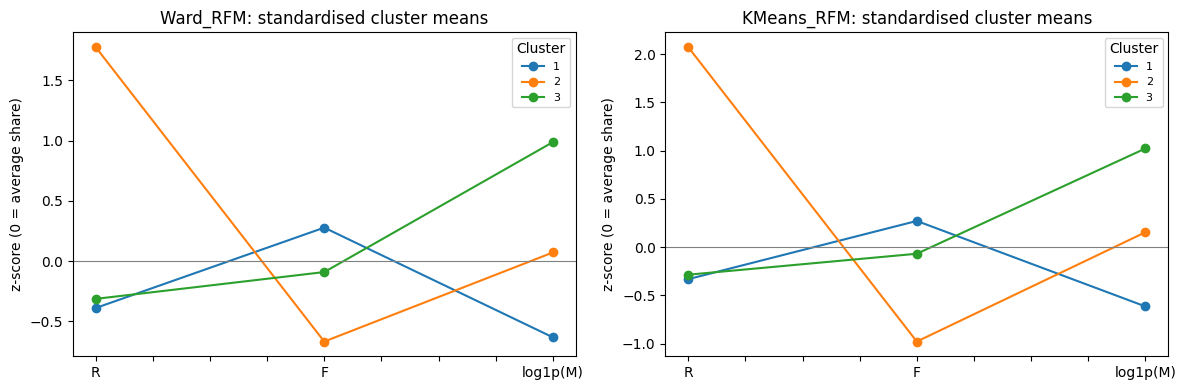

In [ ]:
# Snake plot: standardised cluster means per feature (RFM solutions)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
Z_df = pd.DataFrame(X_rfm, index=feat.index, columns=["R", "F", "log1p(M)"])
for a, col in zip(ax, ["Ward_RFM", "KMeans_RFM"]):
    Z_df.groupby(sol[col]).mean().T.plot(ax=a, marker="o"); a.axhline(0, color="grey", lw=.8)
    a.set_title(f"{col}: standardised cluster means"); a.set_ylabel("z-score (0 = average share)"); a.legend(title="Cluster", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "snake_plot_rfm.png", dpi=150); plt.show()

In [ ]:
# Algorithm comparison on the SAME shares
for m in ["RR", "RFM"]:
    a, b = sol[f"Ward_{m}"], sol[f"KMeans_{m}"]
    print(f"{m}: ARI(Ward, K-means) = {adjusted_rand_score(a, b):.3f}  (k Ward = {a.nunique()}, k K-means = {b.nunique()})")
    print(pd.crosstab(a, b, rownames=["Ward"], colnames=["K-means"]).to_string(), "\n")
# Same-k comparison, to separate 'different algorithm' from 'different k'
for m, X in [("RR", X_rr), ("RFM", X_rfm)]:
    k = K_KM[m.lower()]
    w = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit_predict(X)
    print(f"{m} at k = {k} for both: ARI = {adjusted_rand_score(w, km):.3f}")

RR: ARI(Ward, K-means) = 0.511  (k Ward = 3, k K-means = 3)
K-means    1    2   3
Ward                 
1        148    3  13
2         54  158  17
3          0    2  90 

RFM: ARI(Ward, K-means) = 0.833  (k Ward = 3, k K-means = 3)
K-means    1   2    3
Ward                 
1        249   0    0
2         15  59    8
3          5   5  144 

RR at k = 3 for both: ARI = 0.511
RFM at k = 3 for both: ARI = 0.833


## 5. RFM sensitivity and correlated inputs (2.5)
### 5.1 Correlations among R, F and log1p(M)

In [ ]:
print("Pearson:\n", X_rfm_raw.corr().round(3).to_string())
print("\nSpearman:\n", X_rfm_raw.corr(method="spearman").round(3).to_string())
eig = np.sort(np.linalg.eigvalsh(np.corrcoef(X_rfm.T)))[::-1]
print("\nShare of total standardised variance on each principal axis:", (eig / eig.sum()).round(3))

Pearson:
              R      F  log1p_M
R        1.000 -0.348    0.153
F       -0.348  1.000    0.014
log1p_M  0.153  0.014    1.000

Spearman:
              R      F  log1p_M
R        1.000 -0.201    0.138
F       -0.201  1.000   -0.047
log1p_M  0.138 -0.047    1.000

Share of total standardised variance on each principal axis: [0.458 0.337 0.205]


In [ ]:
k = K_WARD["rfm"]                                              # same k as the selected Ward RFM solution
X_rf = StandardScaler().fit_transform(feat[["R", "F"]])         # re-standardised afresh, same shares
lab_full = sol["Ward_RFM"].values
lab_rf = relabel(AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_rf), feat["M"])
sol["Ward_RF_only"] = lab_rf

ari = adjusted_rand_score(lab_full, lab_rf)
print(f"Adjusted Rand index, Ward RFM vs Ward R+F only (k = {k}, {len(feat)} shares): {ari:.3f}")
print(pd.crosstab(sol["Ward_RFM"], sol["Ward_RF_only"], rownames=["RFM"], colnames=["R+F only"]).to_string())

def traded_value(col):
    g = feat.groupby(sol[col])["M"]
    return pd.DataFrame({"n": g.size(), "M_median_usd_bn": (g.median()/1e9).round(2), "M_mean_usd_bn": (g.mean()/1e9).round(2),
                         "R_median": feat.groupby(sol[col])["R"].median(), "F_mean": feat.groupby(sol[col])["F"].mean().round(2)})
print("\nTraded-value profile, full RFM solution:\n", traded_value("Ward_RFM").to_string())
print("\nTraded-value profile, R+F-only solution:\n", traded_value("Ward_RF_only").to_string())

def eta_sq(col):                                               # share of variance in log1p(M) explained by cluster membership
    y = np.log1p(feat["M"]); ssw = sum(((y[g.index] - y[g.index].mean())**2).sum() for _, g in feat.groupby(sol[col]))
    return 1 - ssw / ((y - y.mean())**2).sum()
print(f"\nVariance of log1p(M) explained by clusters: full RFM = {eta_sq('Ward_RFM'):.2f}, R+F only = {eta_sq('Ward_RF_only'):.2f}")

Adjusted Rand index, Ward RFM vs Ward R+F only (k = 3, 485 shares): 0.291
R+F only    1   2   3
RFM                  
1         182  66   1
2           3   0  79
3          86  59   9

Traded-value profile, full RFM solution:
             n  M_median_usd_bn  M_mean_usd_bn  R_median  F_mean
Ward_RFM                                                       
1         249            11.15          11.75      11.0    3.35
2          82            17.85          47.16      54.5    2.10
3         154            39.70          80.15      11.0    2.86

Traded-value profile, R+F-only solution:
                 n  M_median_usd_bn  M_mean_usd_bn  R_median  F_mean
Ward_RF_only                                                       
1             271            14.93          39.49      11.0    3.85
2             125            17.70          34.34      11.0    1.80
3              89            20.85          46.53      54.0    2.01

Variance of log1p(M) explained by clusters: full RFM = 0.52, R+F only

In [ ]:
# Save everything for Task 3 and for the GitHub repo
out = feat.join(sol)
out.to_csv(DATA / "features_with_clusters.csv")
for name, tbl in {"ward_rr": ward_rr, "ward_rfm": ward_rfm, "kmeans_rr": km_rr, "kmeans_rfm": km_rfm}.items():
    tbl.to_csv(DATA / f"diagnostics_{name}.csv")
for c, p in profiles.items(): p.to_csv(DATA / f"profile_{c}.csv")
print("Saved: features_with_clusters.csv, diagnostics_*.csv, profile_*.csv, figures/*.png")
out.iloc[:, -5:].head()

Saved: features_with_clusters.csv, diagnostics_*.csv, profile_*.csv, figures/*.png


,Ward_RR,KMeans_RR,Ward_RFM,KMeans_RFM,Ward_RF_only
Ticker,,,,,
MMM,2,2,3,1,1
AOS,2,2,1,1,2
ABT,1,1,3,3,2
ABBV,1,1,3,3,1
ACN,2,2,3,3,2


In [ ]:
# Download the files the Task 3 notebook needs (and everything else for GitHub)
try:
    import shutil
    from google.colab import files
    files.download("data/features_with_clusters.csv")       # -> upload into the Task 3 notebook
    shutil.make_archive("task2_outputs", "zip", ".", "data"); shutil.make_archive("task2_figures", "zip", ".", "figures")
    files.download("task2_outputs.zip"); files.download("task2_figures.zip")
except ImportError:
    print("Not in Colab - files are in data/ and figures/.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>